In [1]:
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

device = "cuda" if torch.cuda.is_available() else "cpu"

tfm = transforms.Compose([
    transforms.ToTensor(),                      # image -> numbers 0..1
    transforms.Normalize((0.1307,), (0.3081,))  # MNIST's mean and std
])

train_ds = datasets.MNIST("data", train=True,  download=True, transform=tfm)
test_ds  = datasets.MNIST("data", train=False, download=True, transform=tfm)

train_dl = DataLoader(train_ds, batch_size=128, shuffle=True)
test_dl  = DataLoader(test_ds,  batch_size=256)

100%|██████████| 9.91M/9.91M [00:01<00:00, 6.55MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 153kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.46MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.27MB/s]


In [6]:
class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride, 1, bias=False)
        self.bn1   = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, 1, 1, bias=False)
        self.bn2   = nn.BatchNorm2d(out_ch)

        # the skip path: identity, unless the shape changes
        self.shortcut = nn.Sequential()
        if stride != 1 or in_ch != out_ch:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 1, stride, bias=False),
                nn.BatchNorm2d(out_ch))

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = out + self.shortcut(x)   # <-- the skip connection
        return F.relu(out)

In [7]:
class MiniResNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(1, 16, 3, 1, 1, bias=False),  # 1 channel (grayscale) -> 16
            nn.BatchNorm2d(16), nn.ReLU())
        self.layer1 = ResBlock(16, 16)              # 28x28
        self.layer2 = ResBlock(16, 32, stride=2)    # 14x14
        self.layer3 = ResBlock(32, 64, stride=2)    # 7x7
        self.pool = nn.AdaptiveAvgPool2d(1)         # average each map to 1 number
        self.fc   = nn.Linear(64, 10)               # 10 digit scores

    def forward(self, x):
        x = self.stem(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.pool(x).flatten(1)
        return self.fc(x)

model = MiniResNet().to(device)

In [9]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

In [10]:
for epoch in range(5):
    model.train()
    for images, labels in train_dl:
        images, labels = images.to(device), labels.to(device)

        outputs = model(images)             # 1. guess
        loss = criterion(outputs, labels)   # 2. measure the error

        optimizer.zero_grad()               # 3. clear old gradients
        loss.backward()                     # 4. work out how to improve
        optimizer.step()                    # 5. update weights

    print(f"epoch {epoch+1} done, last loss {loss.item():.4f}")

epoch 1 done, last loss 0.0275
epoch 2 done, last loss 0.0241
epoch 3 done, last loss 0.0431
epoch 4 done, last loss 0.0223
epoch 5 done, last loss 0.0101


In [11]:
model.eval()
correct = 0
with torch.no_grad():
    for images, labels in test_dl:
        images, labels = images.to(device), labels.to(device)
        preds = model(images).argmax(dim=1)
        correct += (preds == labels).sum().item()

print(f"Test accuracy: {100 * correct / len(test_ds):.2f}%")

Test accuracy: 98.90%


In [12]:
img, label = test_ds[0]
pred = model(img.unsqueeze(0).to(device)).argmax(1).item()
print("true:", label, "predicted:", pred)

torch.save(model.state_dict(), "mnist_resnet.pth")

true: 7 predicted: 7


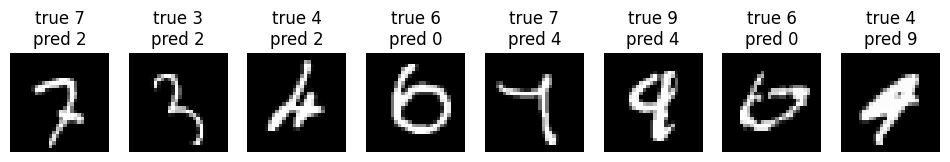

In [13]:
import matplotlib.pyplot as plt

model.eval()
wrong = []
with torch.no_grad():
    for images, labels in test_dl:
        images, labels = images.to(device), labels.to(device)
        preds = model(images).argmax(1)
        for img, y, p in zip(images, labels, preds):
            if y != p and len(wrong) < 8:
                wrong.append((img.cpu(), y.item(), p.item()))

plt.figure(figsize=(12, 3))
for i, (img, y, p) in enumerate(wrong):
    plt.subplot(1, 8, i + 1)
    plt.imshow(img.squeeze(), cmap="gray")
    plt.title(f"true {y}\npred {p}")
    plt.axis("off")
plt.show()